<a href="https://colab.research.google.com/github/Aswini-Dileep/AI-ML-Project/blob/main/AI_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

# Cell 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:

# Cell 2: Load dataset

df = pd.read_csv("/content/synthetic_indian_school_dataset_1000.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [9]:

# Cell 3: Display first five rows

df.head()


,School_ID,State,District,School_Type,Students,Teachers,Study_Groups,Subjects,Classrooms,Computer_Labs,Library_Available,Computers,Student_Teacher_Ratio
0,SCH0001,Odisha,Khordha,Government,625,26,19,10,24,0,1,19,24.04
1,SCH0002,Uttar Pradesh,Varanasi,Government,698,37,24,13,31,0,1,20,18.86
2,SCH0003,West Bengal,Hooghly,Government,1967,66,55,17,64,4,1,77,29.80
3,SCH0004,Tamil Nadu,Salem,Government,549,20,19,11,25,2,0,6,27.45
4,SCH0005,Odisha,Khordha,Private,72,5,3,8,5,1,1,13,14.40


In [10]:

# Cell 4: Check number of rows and columns

print("Number of observations:", df.shape[0])
print("Number of features:", df.shape[1])


Number of observations: 1000
Number of features: 13


In [11]:

# Cell 5: Dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   School_ID              1000 non-null   object 
 1   State                  1000 non-null   object 
 2   District               1000 non-null   object 
 3   School_Type            1000 non-null   object 
 4   Students               1000 non-null   int64  
 5   Teachers               1000 non-null   int64  
 6   Study_Groups           1000 non-null   int64  
 7   Subjects               1000 non-null   int64  
 8   Classrooms             1000 non-null   int64  
 9   Computer_Labs          1000 non-null   int64  
 10  Library_Available      1000 non-null   int64  
 11  Computers              1000 non-null   int64  
 12  Student_Teacher_Ratio  1000 non-null   float64
dtypes: float64(1), int64(8), object(4)
memory usage: 101.7+ KB


In [12]:

# Cell 6: Statistical summary

df.describe()


,Students,Teachers,Study_Groups,Subjects,Classrooms,Computer_Labs,Library_Available,Computers,Student_Teacher_Ratio
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,616.48700,25.162000,18.899000,11.282000,23.113000,1.519000,0.890000,27.348000,26.549020
std,502.86642,22.793624,14.919363,3.002581,17.682333,1.388368,0.313046,23.956686,7.125046
min,45.00000,5.000000,3.000000,5.000000,3.000000,0.000000,0.000000,0.000000,9.000000
25%,202.00000,7.000000,6.000000,9.000000,8.000000,0.000000,1.000000,7.000000,22.040000
50%,530.00000,19.000000,16.000000,11.000000,20.000000,1.000000,1.000000,22.000000,26.000000
75%,807.75000,33.000000,25.000000,13.000000,30.000000,2.000000,1.000000,41.250000,30.000000
max,2314.00000,110.000000,72.000000,20.000000,90.000000,6.000000,1.000000,106.000000,62.860000


In [13]:

# Cell 7: Check missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
School_ID                0
State                    0
District                 0
School_Type              0
Students                 0
Teachers                 0
Study_Groups             0
Subjects                 0
Classrooms               0
Computer_Labs            0
Library_Available        0
Computers                0
Student_Teacher_Ratio    0
dtype: int64


In [14]:

# Cell 8: Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [15]:

# Cell 9: Check duplicate school IDs

print("Duplicate School IDs:", df["School_ID"].duplicated().sum())


Duplicate School IDs: 0


In [16]:

# Cell 10: Select numerical columns

numerical_df = df.select_dtypes(include=["int64", "float64"])

print("Numerical columns:")
print(numerical_df.columns.tolist())


Numerical columns:
['Students', 'Teachers', 'Study_Groups', 'Subjects', 'Classrooms', 'Computer_Labs', 'Library_Available', 'Computers', 'Student_Teacher_Ratio']


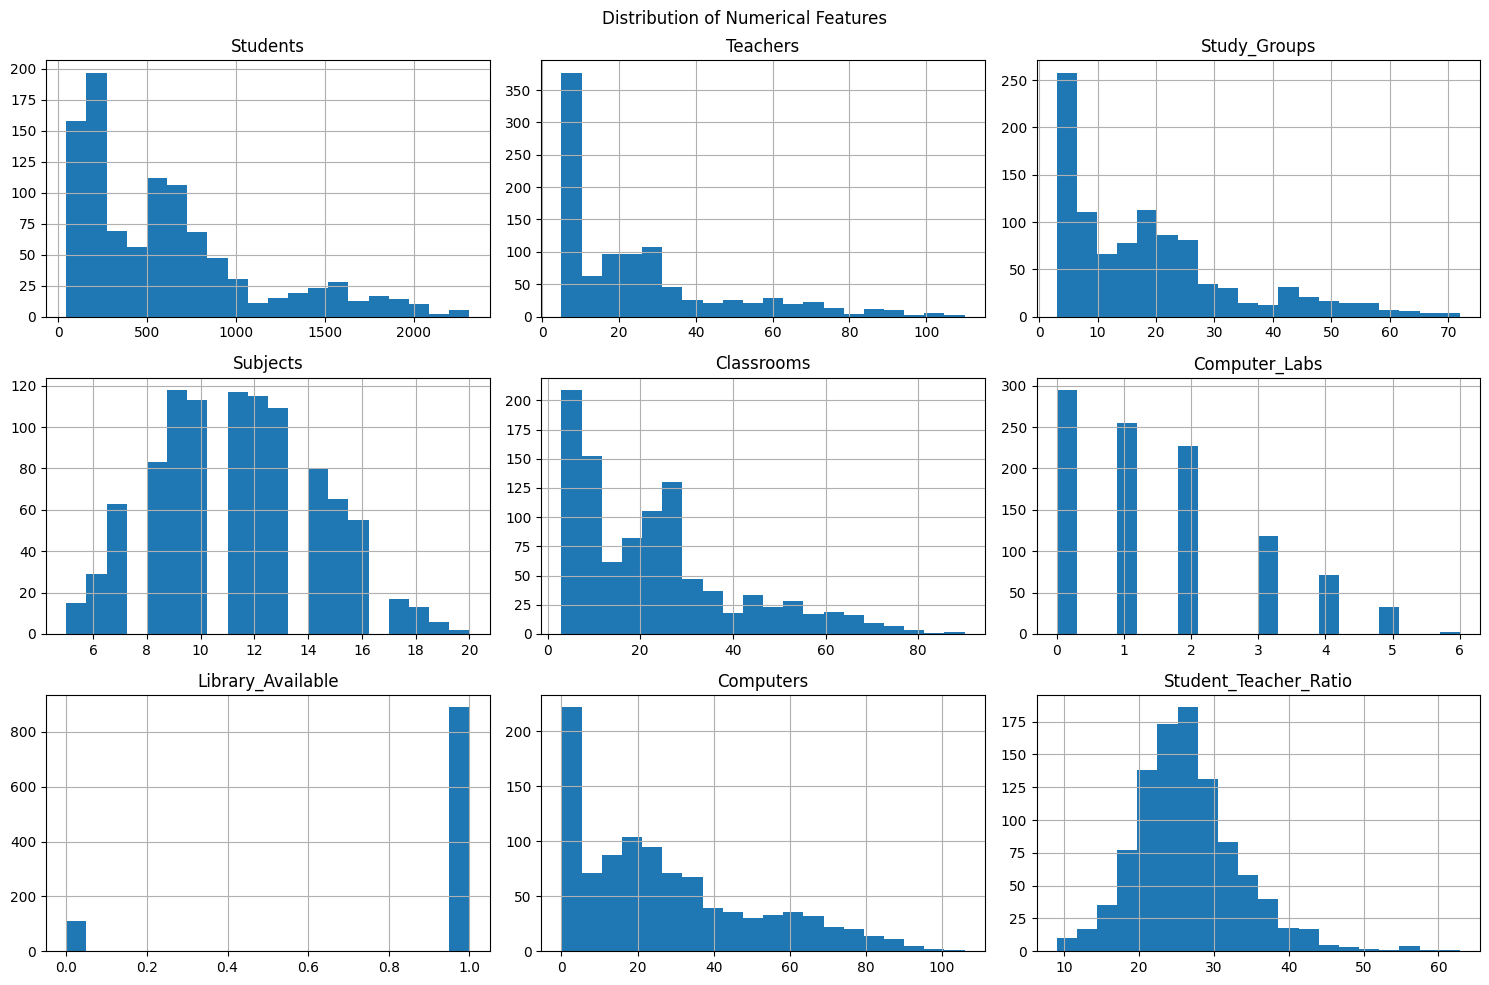

In [17]:

# Cell 11: Plot numerical feature distributions

numerical_df.hist(figsize=(15, 10), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


In [18]:

# Cell 12: Select clustering features

features = [
    "Students",
    "Teachers",
    "Study_Groups",
    "Subjects"
]

X = df[features]

print("Selected features:")
print(X.head())

print("\nDataset shape:", X.shape)


Selected features:
   Students  Teachers  Study_Groups  Subjects
0       625        26            19        10
1       698        37            24        13
2      1967        66            55        17
3       549        20            19        11
4        72         5             3         8

Dataset shape: (1000, 4)


In [19]:

# Cell 13: Apply Min-Max Normalization

scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easy viewing
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled_df.head())


   Students  Teachers  Study_Groups  Subjects
0  0.255619  0.200000      0.231884  0.333333
1  0.287792  0.304762      0.304348  0.533333
2  0.847069  0.580952      0.753623  0.800000
3  0.222124  0.142857      0.231884  0.400000
4  0.011900  0.000000      0.000000  0.200000


In [20]:

# Cell 14: Check minimum and maximum values

print("Minimum values:")
print(X_scaled_df.min())

print("\nMaximum values:")
print(X_scaled_df.max())


Minimum values:
Students        0.0
Teachers        0.0
Study_Groups    0.0
Subjects        0.0
dtype: float64

Maximum values:
Students        1.0
Teachers        1.0
Study_Groups    1.0
Subjects        1.0
dtype: float64


In [21]:

# Experiment 2: Standard K-Means from scratch

def standard_kmeans(X, k, max_iterations=100, tolerance=0.0001):

    # Step 1: Initialize random centroids
    np.random.seed(42)

    random_indices = np.random.choice(
        len(X), k, replace=False
    )

    centroids = X[random_indices]

    for iteration in range(max_iterations):

        # Step 2: Calculate distances
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        # Step 3: Assign each observation to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Step 4: Update centroids
        new_centroids = []

        for cluster in range(k):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:
                new_centroid = cluster_points.mean(axis=0)
            else:
                new_centroid = centroids[cluster]

            new_centroids.append(new_centroid)

        new_centroids = np.array(new_centroids)

        # Step 5: Check convergence
        difference = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        if difference < tolerance:
            break

    return labels, centroids, iteration + 1


In [22]:

# Run Standard K-Means with K = 3

X_array = X_scaled_df.to_numpy()

labels, centroids, iterations = standard_kmeans(
    X_array,
    k=3
)

print("K-Means completed successfully!")
print("Number of clusters:", 3)
print("Number of iterations:", iterations)

print("\nCentroids:")
print(centroids)


K-Means completed successfully!
Number of clusters: 3
Number of iterations: 11

Centroids:
[[0.68647098 0.61829076 0.64497553 0.66269316]
 [0.28201597 0.21046245 0.2648063  0.49551282]
 [0.07134315 0.0256461  0.05281655 0.26004619]]


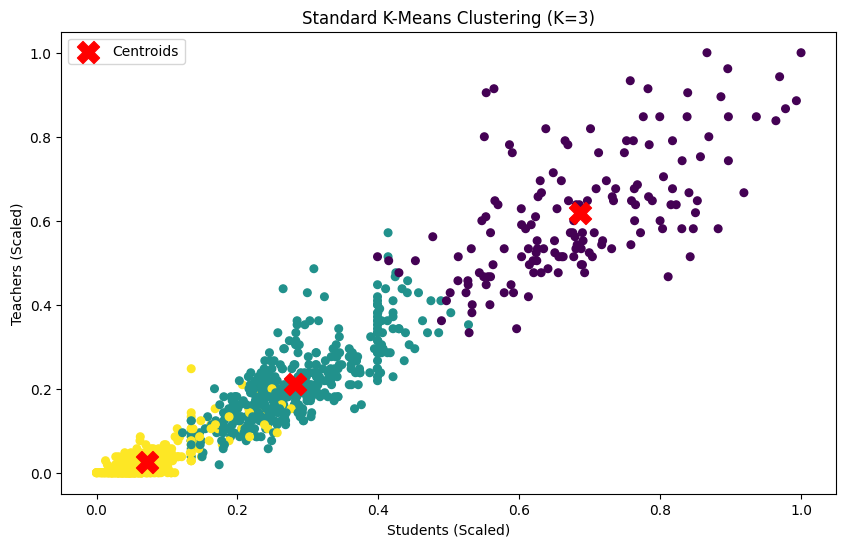

In [23]:

# Cell 15: Visualize K-Means clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=30
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Students (Scaled)")
plt.ylabel("Teachers (Scaled)")
plt.title("Standard K-Means Clustering (K=3)")
plt.legend()
plt.show()


In [24]:

# Cell 16: Calculate SSE

sse = 0

for i in range(len(X_array)):

    assigned_centroid = centroids[labels[i]]

    distance = np.linalg.norm(
        X_array[i] - assigned_centroid
    )

    sse += distance ** 2

print("Sum of Squared Errors (SSE):", sse)


Sum of Squared Errors (SSE): 37.862066102184826


In [25]:

# Cell 17: Calculate Silhouette Score

score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)


Silhouette Score: 0.4957306487065443


In [26]:

# Cell 18: Store baseline experiment results

baseline_results = pd.DataFrame({
    "Method": ["Random Initialization"],
    "K": [3],
    "Iterations": [iterations],
    "SSE": [sse],
    "Silhouette_Score": [score]
})

baseline_results


,Method,K,Iterations,SSE,Silhouette_Score
0,Random Initialization,3,11,37.862066,0.495731


In [27]:

# Cell 19: Standard K-Means using Scikit-learn

from sklearn.cluster import KMeans

sklearn_kmeans = KMeans(
    n_clusters=3,
    init="random",
    n_init=1,
    max_iter=100,
    random_state=42,
    tol=0.0001
)

sklearn_labels = sklearn_kmeans.fit_predict(X_scaled)

sklearn_centroids = sklearn_kmeans.cluster_centers_

print("Scikit-learn K-Means")
print("--------------------")

print("Iterations:", sklearn_kmeans.n_iter_)
print("SSE:", sklearn_kmeans.inertia_)

print(
    "Silhouette Score:",
    silhouette_score(X_scaled, sklearn_labels)
)


Scikit-learn K-Means
--------------------
Iterations: 11
SSE: 37.86206610218481
Silhouette Score: 0.4957306487065443


In [28]:

# Cell 20: Mean-based centroid initialization

def mean_initialization(X, k):

    # Sort observations based on Students (first feature)
    sorted_indices = np.argsort(X[:, 0])

    sorted_data = X[sorted_indices]

    # Divide data into K approximately equal groups
    groups = np.array_split(sorted_data, k)

    # Calculate mean of each group
    initial_centroids = []

    for group in groups:
        centroid = np.mean(group, axis=0)
        initial_centroids.append(centroid)

    return np.array(initial_centroids)


# Generate initial centroids
mean_centroids = mean_initialization(X_array, 3)

print("Initial centroids using Mean:")
print(mean_centroids)


Initial centroids using Mean:
[[0.05125184 0.01203308 0.03254361 0.25708583]
 [0.1994039  0.13459173 0.18353136 0.42662663]
 [0.50554874 0.42997283 0.47578013 0.57317317]]


In [29]:

# Cell 21: K-Means with customizable initial centroids

def standard_kmeans(
    X,
    k,
    max_iterations=100,
    tolerance=0.0001,
    initial_centroids=None
):

    # Step 1: Initialize centroids
    if initial_centroids is None:

        np.random.seed(42)

        random_indices = np.random.choice(
            len(X), k, replace=False
        )

        centroids = X[random_indices].copy()

    else:
        centroids = initial_centroids.copy()

    for iteration in range(max_iterations):

        # Step 2: Calculate distances
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        # Step 3: Assign observations to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Step 4: Update centroids
        new_centroids = []

        for cluster in range(k):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:
                new_centroid = cluster_points.mean(axis=0)
            else:
                new_centroid = centroids[cluster]

            new_centroids.append(new_centroid)

        new_centroids = np.array(new_centroids)

        # Step 5: Check convergence
        difference = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        if difference < tolerance:
            break

    return labels, centroids, iteration + 1


In [30]:

# Cell 22: Run Mean-based K-Means

mean_labels, mean_final_centroids, mean_iterations = standard_kmeans(
    X_array,
    k=3,
    initial_centroids=mean_centroids
)

print("Mean-based K-Means completed!")
print("Number of clusters:", 3)
print("Number of iterations:", mean_iterations)

print("\nFinal centroids:")
print(mean_final_centroids)


Mean-based K-Means completed!
Number of clusters: 3
Number of iterations: 7

Final centroids:
[[0.07134315 0.0256461  0.05281655 0.26004619]
 [0.28201597 0.21046245 0.2648063  0.49551282]
 [0.68647098 0.61829076 0.64497553 0.66269316]]


In [31]:

# Cell 23: Evaluate Mean-based K-Means

mean_sse = 0

for i in range(len(X_array)):

    assigned_centroid = mean_final_centroids[mean_labels[i]]

    distance = np.linalg.norm(
        X_array[i] - assigned_centroid
    )

    mean_sse += distance ** 2

mean_silhouette = silhouette_score(
    X_array,
    mean_labels
)

print("Mean-based Initialization Results")
print("----------------------------------")
print("Iterations:", mean_iterations)
print("SSE:", mean_sse)
print("Silhouette Score:", mean_silhouette)


Mean-based Initialization Results
----------------------------------
Iterations: 7
SSE: 37.862066102184826
Silhouette Score: 0.4957306487065443


In [32]:

# Cell 24: Compare both methods

comparison = pd.DataFrame({
    "Method": [
        "Random Initialization",
        "Mean Initialization"
    ],
    "Iterations": [
        iterations,
        mean_iterations
    ],
    "SSE": [
        sse,
        mean_sse
    ],
    "Silhouette Score": [
        score,
        mean_silhouette
    ]
})

comparison


,Method,Iterations,SSE,Silhouette Score
0,Random Initialization,11,37.862066,0.495731
1,Mean Initialization,7,37.862066,0.495731


In [33]:

# Cell 25: Median-based centroid initialization

def median_initialization(X, k):

    # Sort observations based on Students
    sorted_indices = np.argsort(X[:, 0])

    sorted_data = X[sorted_indices]

    # Divide observations into K groups
    groups = np.array_split(sorted_data, k)

    # Calculate median of each group
    initial_centroids = []

    for group in groups:

        centroid = np.median(group, axis=0)

        initial_centroids.append(centroid)

    return np.array(initial_centroids)


# Generate initial centroids
median_centroids = median_initialization(X_array, 3)

print("Initial centroids using Median:")
print(median_centroids)


Initial centroids using Median:
[[0.05200529 0.         0.02898551 0.26666667]
 [0.214632   0.13333333 0.1884058  0.46666667]
 [0.42485677 0.4        0.4057971  0.6       ]]


In [34]:

# Cell 26: Run Median-based K-Means

median_labels, median_final_centroids, median_iterations = standard_kmeans(
    X_array,
    k=3,
    initial_centroids=median_centroids
)

print("Median-based K-Means completed!")
print("Number of clusters:", 3)
print("Number of iterations:", median_iterations)

print("\nFinal centroids:")
print(median_final_centroids)


Median-based K-Means completed!
Number of clusters: 3
Number of iterations: 7

Final centroids:
[[0.07134315 0.0256461  0.05281655 0.26004619]
 [0.28201597 0.21046245 0.2648063  0.49551282]
 [0.68647098 0.61829076 0.64497553 0.66269316]]


In [35]:

# Cell 27: Evaluate Median-based K-Means

median_sse = 0

for i in range(len(X_array)):

    assigned_centroid = median_final_centroids[median_labels[i]]

    distance = np.linalg.norm(
        X_array[i] - assigned_centroid
    )

    median_sse += distance ** 2


median_silhouette = silhouette_score(
    X_array,
    median_labels
)

print("Median-based Initialization Results")
print("------------------------------------")
print("Iterations:", median_iterations)
print("SSE:", median_sse)
print("Silhouette Score:", median_silhouette)


Median-based Initialization Results
------------------------------------
Iterations: 7
SSE: 37.862066102184826
Silhouette Score: 0.4957306487065443


In [36]:

# Cell 28: Compare Random, Mean and Median

comparison = pd.DataFrame({
    "Method": [
        "Random Initialization",
        "Mean Initialization",
        "Median Initialization"
    ],
    "Iterations": [
        iterations,
        mean_iterations,
        median_iterations
    ],
    "SSE": [
        sse,
        mean_sse,
        median_sse
    ],
    "Silhouette Score": [
        score,
        mean_silhouette,
        median_silhouette
    ]
})

comparison


,Method,Iterations,SSE,Silhouette Score
0,Random Initialization,11,37.862066,0.495731
1,Mean Initialization,7,37.862066,0.495731
2,Median Initialization,7,37.862066,0.495731


In [38]:

# Cell 29: K-Means++ centroid initialization

def kmeans_plus_plus_initialization(X, k, random_state=42):

    rng = np.random.default_rng(random_state)

    # Step 1: Select the first centroid randomly
    first_index = rng.integers(0, len(X))

    centroids = [X[first_index]]

    # Step 2: Select remaining centroids
    for _ in range(1, k):

        # Calculate distances from observations
        # to their nearest existing centroid
        distances = np.linalg.norm(
            X[:, np.newaxis] - np.array(centroids),
            axis=2
        )

        # Find nearest centroid distance for each observation
        min_distances = np.min(distances, axis=1)

        # Square the distances
        squared_distances = min_distances ** 2

        # Calculate selection probabilities
        probabilities = squared_distances / np.sum(
            squared_distances
        )

        # Select next centroid
        next_index = rng.choice(
            len(X),
            p=probabilities
        )

        centroids.append(X[next_index])

    return np.array(centroids)


# Generate K-Means++ initial centroids
kmeanspp_centroids = kmeans_plus_plus_initialization(
    X_array,
    k=3
)

print("K-Means++ Initial Centroids:")
print(kmeanspp_centroids)


K-Means++ Initial Centroids:
[[0.19700309 0.16190476 0.20289855 0.46666667]
 [0.62582636 0.53333333 0.53623188 0.6       ]
 [0.03569855 0.         0.01449275 0.4       ]]


In [39]:

# Cell 30: Run K-Means++ clustering

kmeanspp_labels, kmeanspp_final_centroids, kmeanspp_iterations = standard_kmeans(
    X_array,
    k=3,
    initial_centroids=kmeanspp_centroids
)

print("K-Means++ completed successfully!")
print("Number of clusters:", 3)
print("Number of iterations:", kmeanspp_iterations)

print("\nFinal centroids:")
print(kmeanspp_final_centroids)


K-Means++ completed successfully!
Number of clusters: 3
Number of iterations: 6

Final centroids:
[[0.28201597 0.21046245 0.2648063  0.49551282]
 [0.68647098 0.61829076 0.64497553 0.66269316]
 [0.07134315 0.0256461  0.05281655 0.26004619]]


In [40]:

# Cell 31: Calculate K-Means++ evaluation metrics

kmeanspp_sse = 0

for i in range(len(X_array)):

    assigned_centroid = kmeanspp_final_centroids[
        kmeanspp_labels[i]
    ]

    distance = np.linalg.norm(
        X_array[i] - assigned_centroid
    )

    kmeanspp_sse += distance ** 2


kmeanspp_silhouette = silhouette_score(
    X_array,
    kmeanspp_labels
)

print("K-Means++ Results")
print("------------------")
print("Iterations:", kmeanspp_iterations)
print("SSE:", kmeanspp_sse)
print("Silhouette Score:", kmeanspp_silhouette)


K-Means++ Results
------------------
Iterations: 6
SSE: 37.862066102184826
Silhouette Score: 0.4957306487065443


In [41]:

# Cell 32: Final initialization comparison

comparison = pd.DataFrame({
    "Method": [
        "Random",
        "Mean",
        "Median",
        "K-Means++"
    ],

    "Iterations": [
        iterations,
        mean_iterations,
        median_iterations,
        kmeanspp_iterations
    ],

    "SSE": [
        sse,
        mean_sse,
        median_sse,
        kmeanspp_sse
    ],

    "Silhouette Score": [
        score,
        mean_silhouette,
        median_silhouette,
        kmeanspp_silhouette
    ]
})

comparison


,Method,Iterations,SSE,Silhouette Score
0,Random,11,37.862066,0.495731
1,Mean,7,37.862066,0.495731
2,Median,7,37.862066,0.495731
3,K-Means++,6,37.862066,0.495731


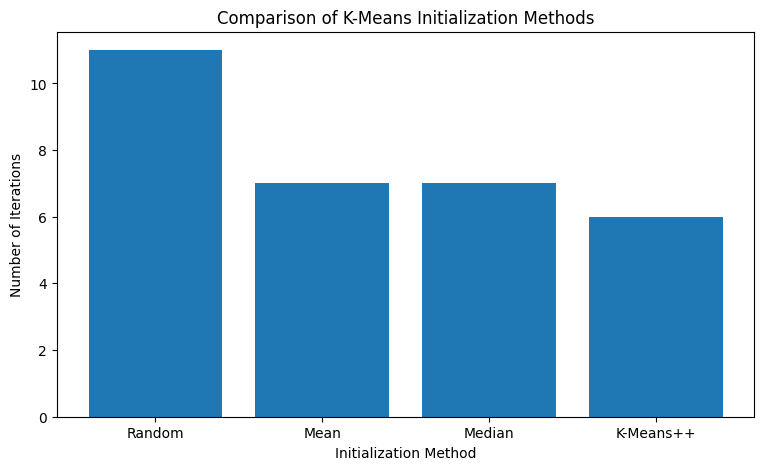

In [42]:

# Cell 33: Compare iteration counts

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Method"],
    comparison["Iterations"]
)

plt.xlabel("Initialization Method")
plt.ylabel("Number of Iterations")
plt.title("Comparison of K-Means Initialization Methods")

plt.show()


In [43]:

# Cell 34: Calculate SSE for different K values

from sklearn.cluster import KMeans

sse_values = []

k_values = range(1, 11)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    model.fit(X_scaled)

    sse_values.append(model.inertia_)

    print(f"K = {k}, SSE = {model.inertia_:.4f}")


K = 1, SSE = 182.8802
K = 2, SSE = 70.5906
K = 3, SSE = 37.8621
K = 4, SSE = 30.5418
K = 5, SSE = 25.5430
K = 6, SSE = 21.3475
K = 7, SSE = 18.2902
K = 8, SSE = 16.6894
K = 9, SSE = 15.4426
K = 10, SSE = 14.2319


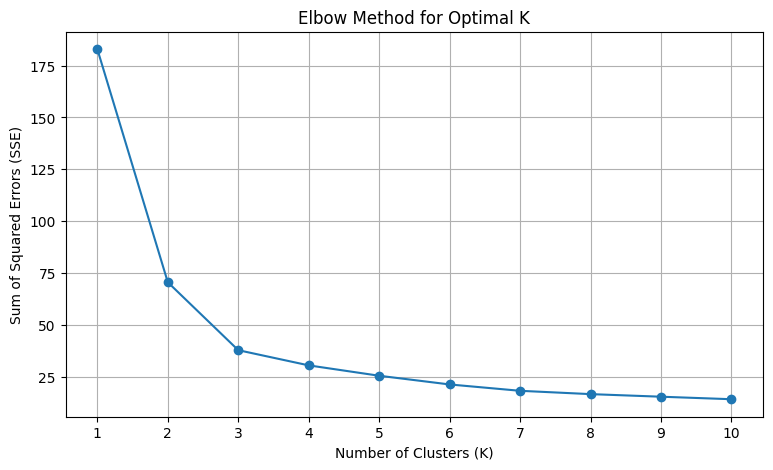

In [44]:

# Cell 35: Plot Elbow Method

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    sse_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Elbow Method for Optimal K")

plt.xticks(k_values)
plt.grid(True)

plt.show()


In [45]:

# Cell 36: Silhouette Score for different K values

silhouette_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels_k = model.fit_predict(X_scaled)

    score_k = silhouette_score(
        X_scaled,
        labels_k
    )

    silhouette_values.append(score_k)

    print(f"K = {k}, Silhouette Score = {score_k:.4f}")


K = 2, Silhouette Score = 0.5822
K = 3, Silhouette Score = 0.4957
K = 4, Silhouette Score = 0.4399
K = 5, Silhouette Score = 0.4254
K = 6, Silhouette Score = 0.3800
K = 7, Silhouette Score = 0.3721
K = 8, Silhouette Score = 0.3495
K = 9, Silhouette Score = 0.3475
K = 10, Silhouette Score = 0.3175


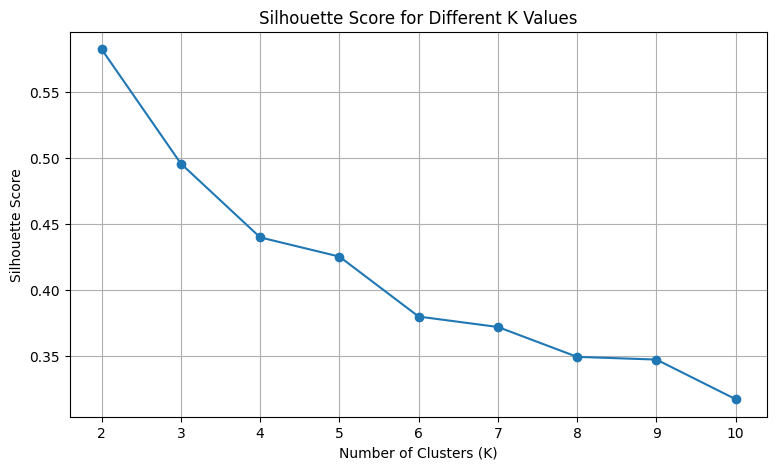

In [46]:

# Cell 37: Plot Silhouette Scores

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()


In [47]:

# Cell 38: Add cluster labels to dataset

df["Cluster"] = labels

print(df[["School_ID", "Students", "Teachers", "Study_Groups", "Subjects", "Cluster"]].head(10))


  School_ID  Students  Teachers  Study_Groups  Subjects  Cluster
0   SCH0001       625        26            19        10        1
1   SCH0002       698        37            24        13        1
2   SCH0003      1967        66            55        17        0
3   SCH0004       549        20            19        11        1
4   SCH0005        72         5             3         8        2
5   SCH0006       950        44            27        17        1
6   SCH0007       619        21            20        10        1
7   SCH0008       528        15            15        12        1
8   SCH0009       206         9             6         8        2
9   SCH0010       865        32            25         9        1


In [48]:

# Cell 39: Count observations in each cluster

cluster_counts = df["Cluster"].value_counts().sort_index()

print("Number of schools in each cluster:")
print(cluster_counts)


Number of schools in each cluster:
Cluster
0    151
1    416
2    433
Name: count, dtype: int64


In [49]:

# Cell 40: Cluster profiling

cluster_profile = df.groupby("Cluster")[[
    "Students",
    "Teachers",
    "Study_Groups",
    "Subjects",
    "Classrooms",
    "Computer_Labs",
    "Computers"
]].mean().round(2)

cluster_profile


,Students,Teachers,Study_Groups,Subjects,Classrooms,Computer_Labs,Computers
Cluster,,,,,,,
0,1602.60,69.92,47.50,14.94,56.43,3.48,65.32
1,684.89,27.10,21.27,12.43,26.29,1.66,28.62
2,206.88,7.69,6.64,8.90,8.44,0.70,12.88


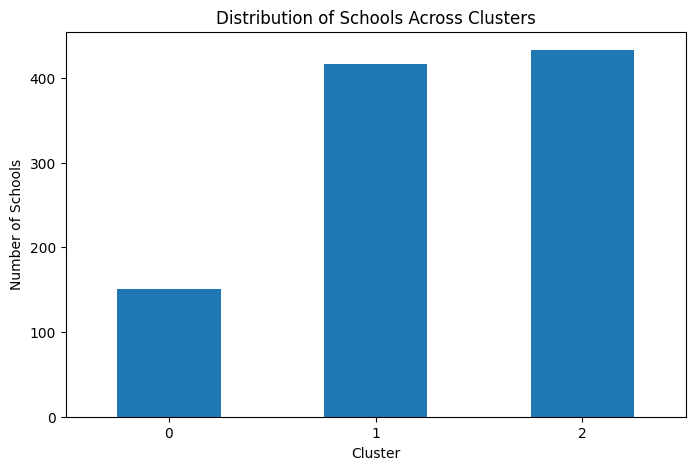

In [50]:

# Cell 41: Visualise cluster distribution

plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar"
)

plt.xlabel("Cluster")
plt.ylabel("Number of Schools")
plt.title("Distribution of Schools Across Clusters")
plt.xticks(rotation=0)

plt.show()


In [51]:

# Cell 42: K-Means with configurable random state

def standard_kmeans(
    X,
    k,
    max_iterations=100,
    tolerance=0.0001,
    initial_centroids=None,
    random_state=42
):

    # Initialize centroids
    if initial_centroids is None:

        rng = np.random.default_rng(random_state)

        random_indices = rng.choice(
            len(X), k, replace=False
        )

        centroids = X[random_indices].copy()

    else:
        centroids = initial_centroids.copy()

    for iteration in range(max_iterations):

        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = []

        for cluster in range(k):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:
                new_centroid = cluster_points.mean(axis=0)
            else:
                new_centroid = centroids[cluster]

            new_centroids.append(new_centroid)

        new_centroids = np.array(new_centroids)

        difference = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        if difference < tolerance:
            break

    return labels, centroids, iteration + 1


In [52]:

# Cell 43: SSE calculation function

def calculate_sse(X, labels, centroids):

    distances = np.linalg.norm(
        X - centroids[labels],
        axis=1
    )

    return np.sum(distances ** 2)


In [53]:

# Cell 44: Repeated experiments

results = []

# Random initialization: 30 runs
for seed in range(30):

    run_labels, run_centroids, run_iterations = standard_kmeans(
        X_array,
        k=3,
        random_state=seed
    )

    run_sse = calculate_sse(
        X_array, run_labels, run_centroids
    )

    run_silhouette = silhouette_score(
        X_array, run_labels
    )

    results.append({
        "Method": "Random",
        "Run": seed + 1,
        "Iterations": run_iterations,
        "SSE": run_sse,
        "Silhouette": run_silhouette
    })


# K-Means++: 30 runs
for seed in range(30):

    initial = kmeans_plus_plus_initialization(
        X_array, 3, random_state=seed
    )

    run_labels, run_centroids, run_iterations = standard_kmeans(
        X_array,
        k=3,
        initial_centroids=initial
    )

    run_sse = calculate_sse(
        X_array, run_labels, run_centroids
    )

    run_silhouette = silhouette_score(
        X_array, run_labels
    )

    results.append({
        "Method": "K-Means++",
        "Run": seed + 1,
        "Iterations": run_iterations,
        "SSE": run_sse,
        "Silhouette": run_silhouette
    })


# Mean initialization: deterministic
run_labels, run_centroids, run_iterations = standard_kmeans(
    X_array, 3, initial_centroids=mean_centroids
)

results.append({
    "Method": "Mean",
    "Run": 1,
    "Iterations": run_iterations,
    "SSE": calculate_sse(X_array, run_labels, run_centroids),
    "Silhouette": silhouette_score(X_array, run_labels)
})


# Median initialization: deterministic
run_labels, run_centroids, run_iterations = standard_kmeans(
    X_array, 3, initial_centroids=median_centroids
)

results.append({
    "Method": "Median",
    "Run": 1,
    "Iterations": run_iterations,
    "SSE": calculate_sse(X_array, run_labels, run_centroids),
    "Silhouette": silhouette_score(X_array, run_labels)
})


results_df = pd.DataFrame(results)

print("Repeated experiments completed!")
print("Total runs:", len(results_df))


Repeated experiments completed!
Total runs: 62


In [54]:

# Cell 45: Stability summary

stability_summary = results_df.groupby("Method").agg({
    "Iterations": ["mean", "std", "min", "max"],
    "SSE": ["mean", "std", "min", "max"],
    "Silhouette": ["mean", "std", "min", "max"]
}).round(4)

stability_summary


Iterations                      SSE                         \
                mean     std min max     mean  std      min      max   
Method                                                                 
K-Means++     7.7333  2.3916   4  15  37.8621  0.0  37.8621  37.8621   
Mean          7.0000     NaN   7   7  37.8621  NaN  37.8621  37.8621   
Median        7.0000     NaN   7   7  37.8621  NaN  37.8621  37.8621   
Random        9.2333  2.6611   4  16  37.8621  0.0  37.8621  37.8621   

          Silhouette                       
                mean  std     min     max  
Method                                     
K-Means++     0.4957  0.0  0.4957  0.4957  
Mean          0.4957  NaN  0.4957  0.4957  
Median        0.4957  NaN  0.4957  0.4957  
Random        0.4957  0.0  0.4957  0.4957

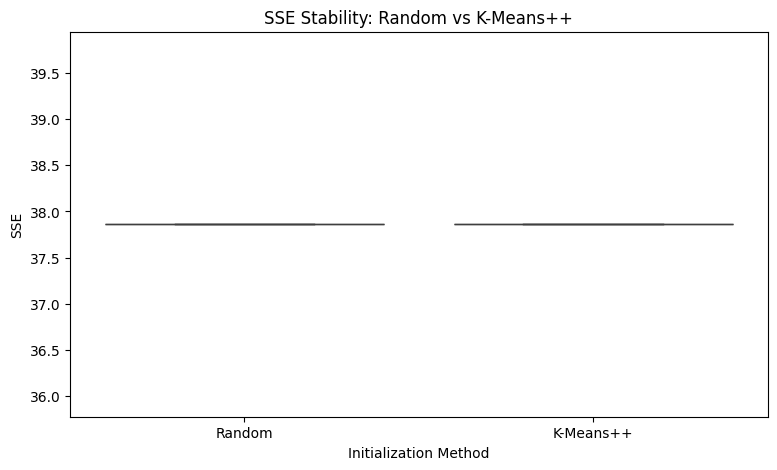

In [57]:

# Cell 46: Compare SSE variation

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=results_df[
        results_df["Method"].isin(["Random", "K-Means++"])
    ],
    x="Method",
    y="SSE"
)

plt.title("SSE Stability: Random vs K-Means++")
plt.xlabel("Initialization Method")
plt.ylabel("SSE")

plt.show()


In [59]:

import time


In [60]:

# Cell 47: Measure execution time for all methods

timing_results = []

number_of_runs = 30

for method in ["Random", "Mean", "Median", "K-Means++"]:

    for seed in range(number_of_runs):

        start_time = time.perf_counter()

        if method == "Random":

            run_labels, run_centroids, run_iterations = standard_kmeans(
                X_array,
                k=3,
                random_state=seed
            )

        elif method == "Mean":

            run_labels, run_centroids, run_iterations = standard_kmeans(
                X_array,
                k=3,
                initial_centroids=mean_centroids
            )

        elif method == "Median":

            run_labels, run_centroids, run_iterations = standard_kmeans(
                X_array,
                k=3,
                initial_centroids=median_centroids
            )

        else:

            initial = kmeans_plus_plus_initialization(
                X_array,
                k=3,
                random_state=seed
            )

            run_labels, run_centroids, run_iterations = standard_kmeans(
                X_array,
                k=3,
                initial_centroids=initial
            )

        end_time = time.perf_counter()

        elapsed_time = end_time - start_time

        timing_results.append({
            "Method": method,
            "Run": seed + 1,
            "Iterations": run_iterations,
            "SSE": calculate_sse(
                X_array, run_labels, run_centroids
            ),
            "Execution_Time": elapsed_time
        })

timing_df = pd.DataFrame(timing_results)

print("Execution-time experiments completed!")
print("Total runs:", len(timing_df))


Execution-time experiments completed!
Total runs: 120


In [61]:

# Cell 48: Summarise execution time

runtime_summary = timing_df.groupby("Method").agg({
    "Execution_Time": ["mean", "std", "min", "max"],
    "Iterations": ["mean", "std"],
    "SSE": ["mean", "std"]
}).round(6)

runtime_summary


Execution_Time                               Iterations            \
                    mean       std       min       max       mean       std   
Method                                                                        
K-Means++       0.002114  0.000566  0.001150  0.003320   7.733333  2.391556   
Mean            0.001670  0.000409  0.001232  0.002499   7.000000  0.000000   
Median          0.001373  0.000243  0.001238  0.002242   7.000000  0.000000   
Random          0.003540  0.001260  0.001107  0.006704   9.233333  2.661129   

                 SSE       
                mean  std  
Method                     
K-Means++  37.862066  0.0  
Mean       37.862066  0.0  
Median     37.862066  0.0  
Random     37.862066  0.0

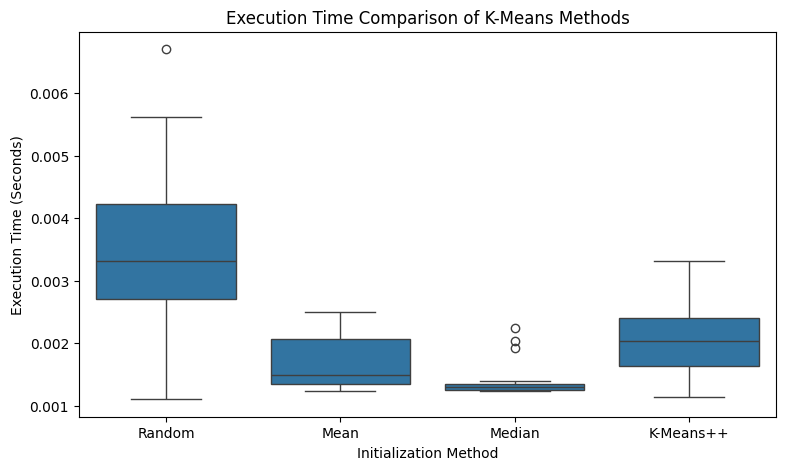

In [62]:

# Cell 49: Execution-time comparison

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=timing_df,
    x="Method",
    y="Execution_Time"
)

plt.title("Execution Time Comparison of K-Means Methods")
plt.xlabel("Initialization Method")
plt.ylabel("Execution Time (Seconds)")

plt.show()


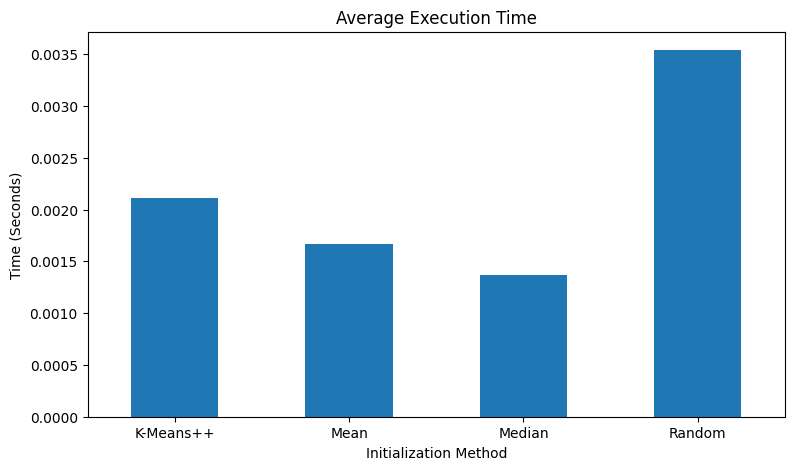

In [63]:

# Cell 50: Average execution time graph

average_times = timing_df.groupby(
    "Method"
)["Execution_Time"].mean()

plt.figure(figsize=(9, 5))

average_times.plot(kind="bar")

plt.title("Average Execution Time")
plt.xlabel("Initialization Method")
plt.ylabel("Time (Seconds)")
plt.xticks(rotation=0)

plt.show()
